# Sumativa 3 — Cierre y comunicación del proyecto

**Curso:** MCDI501 — Estadística Computacional para la Toma de Decisiones  
**Proyecto:** *Online Shoppers Purchasing Intention*  
**Integrantes:** Verónica Durán Cisterna · Raúl Moya Arriagada · Daniela Rojas Vilches · Manuel Sánchez Cárcamo  
**Docente:** Dr. Jean Paul Maidana González

## Pregunta de investigación
> **¿Qué características del comportamiento de navegación de los usuarios se relacionan con la probabilidad de que una sesión de comercio electrónico termine en una compra?**

## Propósito
Integrar de forma trazable **S1 → S2 → S3**, comparar estrategias de manejo de faltantes, construir tres modelos de regresión logística, seleccionar y diagnosticar el mejor modelo, evaluar su estabilidad mediante bootstrap y analizar el impacto de la imputación.

El alcance es **asociativo y predictivo**, no causal.


## 1. Librerías y reproducibilidad

Se mantiene `RANDOM_STATE = 42`, utilizado en F2. El experimento MCAR usa exactamente las mismas variables y regla: 12 % de valores ocultados en `ProductRelated_Duration` y `ExitRates`.


In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats

from statsmodels.stats.outliers_influence import variance_inflation_factor, OLSInfluence
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, roc_curve, mean_absolute_error,
    mean_squared_error
)
from sklearn.linear_model import LogisticRegression

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
MISSING_RATE = 0.12
BOOTSTRAP_B = 1000
np.random.seed(RANDOM_STATE)

print("Semilla:", RANDOM_STATE)
print("MCAR:", f"{MISSING_RATE:.0%}")
print("Bootstrap:", BOOTSTRAP_B)


Semilla: 42
MCAR: 12%
Bootstrap: 1000


## 2. Carga del dataset original

S1 estableció que la base original contiene **12.330 sesiones, 18 variables y ningún valor faltante**. Por instrucción del curso para datasets completos, en F2 se introdujo faltante controlado MCAR. S3 debe trabajar con la misma versión reproducible.


In [2]:
candidatos = [
    Path("data/raw/online_shoppers_intention.csv"),
    Path("../data/raw/online_shoppers_intention.csv"),
    Path("../../data/raw/online_shoppers_intention.csv")
]
DATA_PATH = next((p for p in candidatos if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("No se encontró data/raw/online_shoppers_intention.csv")

df_original = pd.read_csv(DATA_PATH)
print("Archivo:", DATA_PATH.resolve())
print("Dimensiones:", df_original.shape)
print("Faltantes originales:", int(df_original.isna().sum().sum()))
display(df_original.head())

assert df_original.shape == (12330, 18)
assert df_original.isna().sum().sum() == 0


Archivo: C:\Users\eliza\Desktop\ESTUDIOS\MAGÍSTER\2 ESTADÍSITICAS COMPUTACIONAL\Proyecto Estadística\Online-Shoppers-Purchasing-Intention\data\raw\online_shoppers_intention.csv
Dimensiones: (12330, 18)
Faltantes originales: 0


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


## 3. Trazabilidad S1 → S2 → S3

### S1
- `Revenue` está desbalanceada: aproximadamente 15,47 % de sesiones terminan en compra.
- `PageValues` presentó una asociación especialmente fuerte con `Revenue`.
- `VisitorType` presentó asociación significativa, aunque de magnitud pequeña.
- Se observaron distribuciones asimétricas y valores extremos.
- Correlaciones altas: `BounceRates`–`ExitRates`, `ProductRelated`–`ProductRelated_Duration`, entre otras.

### S2
El remuestreo confirmó estabilidad en:
- `BounceRates`–`ExitRates`: r ≈ 0,913.
- `ProductRelated`–`ProductRelated_Duration`: r ≈ 0,861.
- `Informational`–`Informational_Duration`: r ≈ 0,619.
- `Administrative`–`Administrative_Duration`: r ≈ 0,602.

El jackknife mostró que los valores extremos afectan globalmente algunos estimadores, pero ninguna observación individual domina la media. Por ello **no se eliminan outliers automáticamente**.

### F2
Se introdujo 12 % MCAR en `ProductRelated_Duration` y `ExitRates`, se aplicó mediana y se obtuvo un primer modelo logístico. S3 amplía ese flujo.


## 4. Reproducción exacta del escenario MCAR de F2

El mecanismo es **MCAR** porque cada observación tiene igual probabilidad de ser ocultada y la selección no depende de su valor, de otros predictores ni de `Revenue`. La variable objetivo nunca se elimina ni se usa para generar la máscara.


In [3]:
VARIABLES_MCAR = ["ProductRelated_Duration", "ExitRates"]

df_mcar = df_original.copy()
valores_verdaderos = df_original[VARIABLES_MCAR].copy()
indices_mcar = {}

for i, variable in enumerate(VARIABLES_MCAR):
    rng = np.random.default_rng(RANDOM_STATE + i)
    n_missing = round(MISSING_RATE * len(df_mcar))
    idx = rng.choice(df_mcar.index.to_numpy(), size=n_missing, replace=False)
    indices_mcar[variable] = idx
    df_mcar.loc[idx, variable] = np.nan

resumen = pd.DataFrame({
    "Variable": VARIABLES_MCAR,
    "n_faltantes": [df_mcar[v].isna().sum() for v in VARIABLES_MCAR],
    "porcentaje": [100*df_mcar[v].isna().mean() for v in VARIABLES_MCAR]
})
display(resumen.round(2))
assert df_mcar["Revenue"].isna().sum() == 0


,Variable,n_faltantes,porcentaje
0,ProductRelated_Duration,1480,12.0
1,ExitRates,1480,12.0


# PARTE I — Manejo inteligente de datos faltantes

## 5. Tres estrategias

Se construirán tres datasets:

1. **Eliminación completa:** se eliminan filas con faltantes en las variables MCAR.
2. **Imputación simple:** mediana.
3. **Imputación mediante regresión lineal múltiple:** cada variable faltante se estima usando predictores seleccionados desde S1/S2.

Para evitar fuga de información durante la evaluación predictiva, más adelante cada estrategia se aplicará respetando la separación entrenamiento/prueba. En esta primera comparación descriptiva se construyen las versiones completas para estudiar tamaño muestral, distribución y correlaciones.


In [4]:
# 1) Eliminación
df_delete = df_mcar.dropna(subset=VARIABLES_MCAR).copy()

# 2) Mediana (comparación descriptiva global; el modelamiento posterior será train-only)
df_median = df_mcar.copy()
for v in VARIABLES_MCAR:
    df_median[v] = df_median[v].fillna(df_median[v].median())

print("Original:", len(df_original))
print("Eliminación:", len(df_delete))
print("Mediana:", len(df_median))


Original: 12330
Eliminación: 9558
Mediana: 12330


## 6. Imputación por regresión múltiple

Predictores elegidos según relaciones observadas y validadas:

### `ProductRelated_Duration`
- `ProductRelated`: correlación fuerte y estable en S2.
- `Administrative_Duration`
- `Informational_Duration`
- `PageValues`

### `ExitRates`
- `BounceRates`: correlación muy fuerte y estable en S2.
- `PageValues`
- `ProductRelated_Duration`
- `SpecialDay`

`Revenue` **no se utiliza para imputar**, evitando usar el objetivo como predictor del proceso de imputación.


In [5]:
REG_PREDICTORS = {
    "ProductRelated_Duration": [
        "ProductRelated", "Administrative_Duration",
        "Informational_Duration", "PageValues"
    ],
    "ExitRates": [
        "BounceRates", "PageValues",
        "ProductRelated_Duration", "SpecialDay"
    ]
}

def regression_impute_fit_transform(train_df, other_df=None):
    """Ajusta las regresiones SOLO con train_df y transforma train y, opcionalmente, other_df."""
    train_imp = train_df.copy()
    other_imp = None if other_df is None else other_df.copy()
    fitted = {}

    # Primero ProductRelated_Duration; luego ExitRates puede usarla ya imputada.
    for target in VARIABLES_MCAR:
        predictors = REG_PREDICTORS[target]
        complete = train_imp[target].notna() & train_imp[predictors].notna().all(axis=1)

        X_fit = sm.add_constant(train_imp.loc[complete, predictors].astype(float), has_constant="add")
        y_fit = train_imp.loc[complete, target].astype(float)
        reg = sm.OLS(y_fit, X_fit).fit()
        fitted[target] = reg

        miss_train = train_imp[target].isna()
        if miss_train.any():
            Xmiss = sm.add_constant(train_imp.loc[miss_train, predictors].astype(float), has_constant="add")
            pred = reg.predict(Xmiss)
            # Las variables analizadas no admiten valores negativos.
            train_imp.loc[miss_train, target] = np.maximum(pred, 0)

        if other_imp is not None:
            miss_other = other_imp[target].isna()
            if miss_other.any():
                # Si ExitRates usa ProductRelated_Duration, ésta ya fue imputada en la iteración anterior.
                Xmiss = sm.add_constant(other_imp.loc[miss_other, predictors].astype(float), has_constant="add")
                pred = reg.predict(Xmiss)
                other_imp.loc[miss_other, target] = np.maximum(pred, 0)

    return train_imp, other_imp, fitted

df_regression, _, modelos_imputacion_global = regression_impute_fit_transform(df_mcar)

print("Faltantes tras imputación por regresión:",
      int(df_regression[VARIABLES_MCAR].isna().sum().sum()))
for target, reg in modelos_imputacion_global.items():
    print(f"\n{target}: R²={reg.rsquared:.4f}, R² ajustado={reg.rsquared_adj:.4f}")


Faltantes tras imputación por regresión: 0

ProductRelated_Duration: R²=0.7605, R² ajustado=0.7604

ExitRates: R²=0.8502, R² ajustado=0.8501


## 7. Diagnóstico de los modelos de imputación

Para cada regresión de imputación se revisan:
- R² y R² ajustado;
- normalidad aproximada de residuos mediante Q-Q plot;
- homocedasticidad visual residuos vs. ajustados;
- VIF de predictores.

Estos diagnósticos se utilizan como evidencia de calidad de la imputación, reconociendo que el objetivo principal es estimar valores faltantes y no realizar inferencia causal.



MODELO DE IMPUTACIÓN: ProductRelated_Duration
                               OLS Regression Results                              
Dep. Variable:     ProductRelated_Duration   R-squared:                       0.760
Model:                                 OLS   Adj. R-squared:                  0.760
Method:                      Least Squares   F-statistic:                     8609.
Date:                     Fri, 23 Oct 2026   Prob (F-statistic):               0.00
Time:                             20:31:03   Log-Likelihood:                -89744.
No. Observations:                    10850   AIC:                         1.795e+05
Df Residuals:                        10845   BIC:                         1.795e+05
Df Model:                                4                                         
Covariance Type:                 nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
---------------------

,Variable,VIF
0,ProductRelated,1.159
1,Administrative_Duration,1.132
2,Informational_Duration,1.128
3,PageValues,1.006


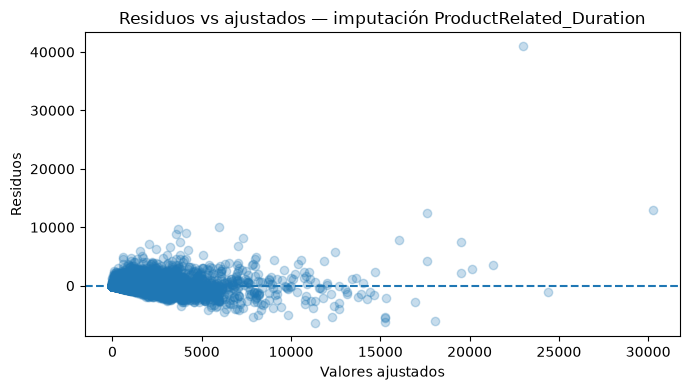

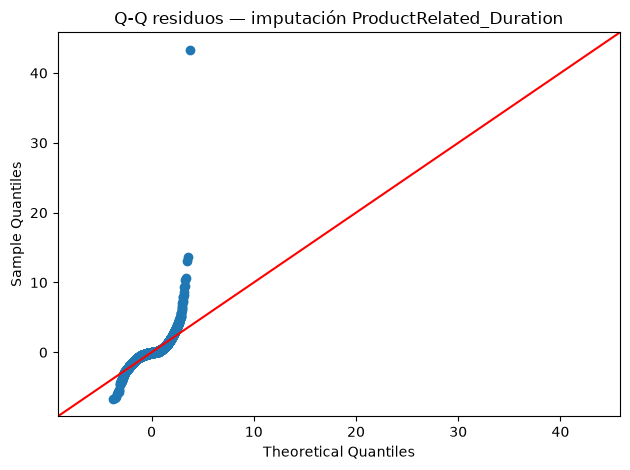


MODELO DE IMPUTACIÓN: ExitRates
                            OLS Regression Results                            
Dep. Variable:              ExitRates   R-squared:                       0.850
Model:                            OLS   Adj. R-squared:                  0.850
Method:                 Least Squares   F-statistic:                 1.539e+04
Date:                Fri, 23 Oct 2026   Prob (F-statistic):               0.00
Time:                        20:31:04   Log-Likelihood:                 27604.
No. Observations:               10850   AIC:                        -5.520e+04
Df Residuals:                   10845   BIC:                        -5.516e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------

,Variable,VIF
0,BounceRates,1.053
1,PageValues,1.020
2,ProductRelated_Duration,1.036
3,SpecialDay,1.010


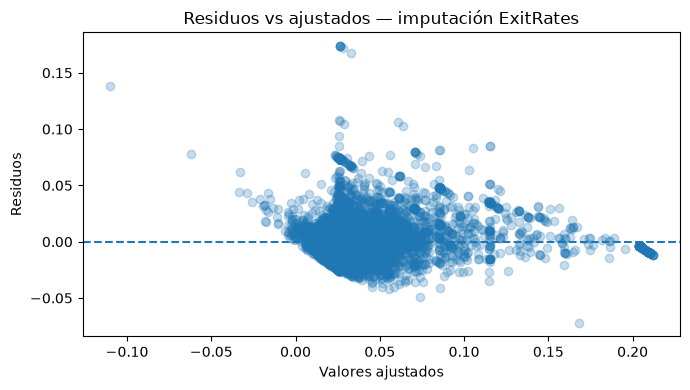

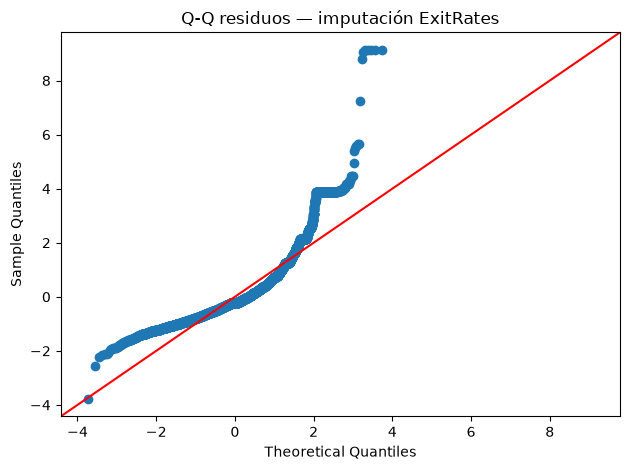

In [6]:
for target, reg in modelos_imputacion_global.items():
    print("\n", "="*70)
    print("MODELO DE IMPUTACIÓN:", target)
    print(reg.summary())

    pred = REG_PREDICTORS[target]
    Xc = df_mcar.loc[df_mcar[target].notna(), pred].dropna().astype(float)
    vif = pd.DataFrame({
        "Variable": Xc.columns,
        "VIF": [variance_inflation_factor(Xc.values, i) for i in range(Xc.shape[1])]
    })
    display(vif.round(3))

    plt.figure(figsize=(7,4))
    plt.scatter(reg.fittedvalues, reg.resid, alpha=.25)
    plt.axhline(0, linestyle="--")
    plt.xlabel("Valores ajustados")
    plt.ylabel("Residuos")
    plt.title(f"Residuos vs ajustados — imputación {target}")
    plt.tight_layout()
    plt.show()

    sm.qqplot(reg.resid, line="45", fit=True)
    plt.title(f"Q-Q residuos — imputación {target}")
    plt.tight_layout()
    plt.show()


## 8. Error real de imputación: mediana vs. regresión

Como los faltantes fueron generados artificialmente, conocemos el valor verdadero ocultado. Esto permite comparar objetivamente **MAE y RMSE**.


In [7]:
errores_imp = []

for v in VARIABLES_MCAR:
    idx = indices_mcar[v]
    real = valores_verdaderos.loc[idx, v]

    pred_med = df_median.loc[idx, v]
    pred_reg = df_regression.loc[idx, v]

    for metodo, pred in [("Mediana", pred_med), ("Regresión", pred_reg)]:
        errores_imp.append({
            "Variable": v,
            "Método": metodo,
            "MAE": mean_absolute_error(real, pred),
            "RMSE": np.sqrt(mean_squared_error(real, pred))
        })

tabla_error = pd.DataFrame(errores_imp)
display(tabla_error.round(4))


,Variable,Método,MAE,RMSE
0,ProductRelated_Duration,Mediana,982.0408,1860.8516
1,ProductRelated_Duration,Regresión,469.3834,832.3291
2,ExitRates,Mediana,0.0271,0.0471
3,ExitRates,Regresión,0.0135,0.0195


## 9. Comparación de tamaño, distribución y preservación de correlaciones

La pauta exige comparar las tres estrategias en tamaño muestral, distribución y preservación de las correlaciones de S1. Se usan como referencia los pares más relevantes validados en S2.


In [8]:
datasets_imp = {
    "Original": df_original,
    "Eliminación": df_delete,
    "Mediana": df_median,
    "Regresión": df_regression
}

filas = []
for nombre, d in datasets_imp.items():
    for v in VARIABLES_MCAR:
        filas.append({
            "Dataset": nombre,
            "Variable": v,
            "n": d[v].notna().sum(),
            "Media": d[v].mean(),
            "Mediana": d[v].median(),
            "DE": d[v].std(),
            "Q1": d[v].quantile(.25),
            "Q3": d[v].quantile(.75)
        })
display(pd.DataFrame(filas).round(4))

corr_rows = []
for nombre, d in datasets_imp.items():
    corr_rows.append({
        "Dataset": nombre,
        "r_BounceRates_ExitRates": d[["BounceRates","ExitRates"]].corr().iloc[0,1],
        "r_ProductRelated_Duration": d[["ProductRelated","ProductRelated_Duration"]].corr().iloc[0,1]
    })
tabla_corr = pd.DataFrame(corr_rows)
display(tabla_corr.round(4))


,Dataset,Variable,n,Media,Mediana,DE,Q1,Q3
0,Original,ProductRelated_Duration,12330,1194.7462,598.9369,1913.6693,184.1375,1464.1572
1,Original,ExitRates,12330,0.0431,0.0252,0.0486,0.0143,0.0500
2,Eliminación,ProductRelated_Duration,9558,1195.4977,592.0750,1955.4739,183.0238,1462.6068
3,Eliminación,ExitRates,9558,0.0435,0.0254,0.0491,0.0143,0.0500
4,Mediana,ProductRelated_Duration,12330,1122.8589,597.1667,1824.0634,226.0641,1287.9319
5,Mediana,ExitRates,12330,0.0413,0.0254,0.0464,0.0155,0.0439
6,Regresión,ProductRelated_Duration,12330,1195.4227,602.5417,1900.2560,192.5000,1460.4890
7,Regresión,ExitRates,12330,0.0430,0.0260,0.0481,0.0154,0.0481


,Dataset,r_BounceRates_ExitRates,r_ProductRelated_Duration
0,Original,0.9130,0.8609
1,Eliminación,0.9150,0.8566
2,Mediana,0.8673,0.8015
3,Regresión,0.9220,0.8706


### Criterio para escoger estrategia

Se priorizará la estrategia que:
1. preserve mejor las relaciones observadas en S1/S2;
2. presente menor MAE/RMSE cuando corresponda;
3. evite pérdida innecesaria de muestra;
4. mantenga coherencia estadística y sustantiva.

El código siguiente selecciona automáticamente entre **mediana** y **regresión** usando el RMSE promedio. La eliminación se conserva como estrategia comparativa, pero no se prioriza si supone pérdida de observaciones.


In [9]:
rmse_prom = tabla_error.groupby("Método")["RMSE"].mean()
METODO_PRINCIPAL = rmse_prom.idxmin()
print("RMSE promedio:")
display(rmse_prom.to_frame())
print("Estrategia principal sugerida:", METODO_PRINCIPAL)


RMSE promedio:


,RMSE
Método,
Mediana,930.449346
Regresión,416.174263


Estrategia principal sugerida: Regresión


# PARTE II — Clasificación mediante regresión logística

## 10. Partición 70/30

Para mantener comparabilidad entre modelos, se utiliza una única partición estratificada de índices. Las imputaciones de mediana/regresión para el modelamiento se ajustan **solo con entrenamiento**, evitando fuga de información.


In [10]:
indices = df_mcar.index
train_idx, test_idx = train_test_split(
    indices,
    test_size=.30,
    random_state=RANDOM_STATE,
    stratify=df_mcar["Revenue"].astype(int)
)

train_raw = df_mcar.loc[train_idx].copy()
test_raw = df_mcar.loc[test_idx].copy()

# Mediana train-only
train_med = train_raw.copy()
test_med = test_raw.copy()
for v in VARIABLES_MCAR:
    med = train_med[v].median()
    train_med[v] = train_med[v].fillna(med)
    test_med[v] = test_med[v].fillna(med)

# Regresión train-only
train_reg, test_reg, modelos_imp_train = regression_impute_fit_transform(train_raw, test_raw)

# Eliminación
train_del = train_raw.dropna(subset=VARIABLES_MCAR).copy()
test_del = test_raw.dropna(subset=VARIABLES_MCAR).copy()

if METODO_PRINCIPAL == "Regresión":
    train_main, test_main = train_reg, test_reg
else:
    train_main, test_main = train_med, test_med

print("Método principal:", METODO_PRINCIPAL)
print("Train/Test principal:", len(train_main), len(test_main))
print("Eliminación Train/Test:", len(train_del), len(test_del))


Método principal: Regresión
Train/Test principal: 8631 3699
Eliminación Train/Test: 6695 2863


## 11. Outliers

S1/S2 identificaron asimetría y valores extremos, pero S2 mostró que ninguna observación individual domina los estimadores. Por ello **se conservan los outliers**. La decisión evita eliminar sesiones reales sin evidencia de error y se acompaña de estandarización de variables numéricas.


## 12. Preparación común de predictores

Para facilitar la comparación de modelos se construye una matriz amplia de candidatos. Se excluye `Revenue`. Las categorías se codifican con `get_dummies(drop_first=True)` y las variables numéricas continuas seleccionadas se estandarizan usando parámetros aprendidos en entrenamiento.


In [11]:
CANDIDATOS = [
    "Administrative", "Administrative_Duration",
    "Informational", "Informational_Duration",
    "ProductRelated", "ProductRelated_Duration",
    "BounceRates", "ExitRates", "PageValues", "SpecialDay",
    "VisitorType", "Weekend"
]

NUM_SCALE = [
    "Administrative", "Administrative_Duration",
    "Informational", "Informational_Duration",
    "ProductRelated", "ProductRelated_Duration",
    "BounceRates", "ExitRates", "PageValues", "SpecialDay"
]

def preparar_matrices(train_df, test_df):
    tr = train_df[CANDIDATOS].copy()
    te = test_df[CANDIDATOS].copy()

    tr["Weekend"] = tr["Weekend"].astype(int)
    te["Weekend"] = te["Weekend"].astype(int)

    combinado = pd.concat([tr.assign(_set="train"), te.assign(_set="test")])
    combinado = pd.get_dummies(combinado, columns=["VisitorType"], drop_first=True, dtype=float)

    tr2 = combinado[combinado["_set"]=="train"].drop(columns="_set")
    te2 = combinado[combinado["_set"]=="test"].drop(columns="_set")

    scaler = StandardScaler()
    tr2[NUM_SCALE] = scaler.fit_transform(tr2[NUM_SCALE])
    te2[NUM_SCALE] = scaler.transform(te2[NUM_SCALE])

    return tr2.astype(float), te2.astype(float), scaler

Xtr_all, Xte_all, scaler_main = preparar_matrices(train_main, test_main)
ytr = train_main["Revenue"].astype(int)
yte = test_main["Revenue"].astype(int)

print("Candidatos después de codificación:", list(Xtr_all.columns))


Candidatos después de codificación: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Weekend', 'VisitorType_Other', 'VisitorType_Returning_Visitor']


## 13. Modelo 1 — selección informada por S1/S2

Replica la lógica sustentada en las fases previas:
- `PageValues`
- `ExitRates`
- `ProductRelated_Duration`
- `VisitorType`
- `Weekend`

Se evita usar simultáneamente pares fuertemente correlacionados.


In [12]:
M1_VARS = [
    "PageValues", "ExitRates", "ProductRelated_Duration",
    "VisitorType_Other", "VisitorType_Returning_Visitor", "Weekend"
]

def fit_logit(X, y, vars_):
    Xs = sm.add_constant(X[vars_], has_constant="add")
    return sm.Logit(y, Xs).fit(disp=False)

m1 = fit_logit(Xtr_all, ytr, M1_VARS)
print(m1.summary())


                           Logit Regression Results                           
Dep. Variable:                Revenue   No. Observations:                 8631
Model:                          Logit   Df Residuals:                     8624
Method:                           MLE   Df Model:                            6
Date:                Fri, 23 Oct 2026   Pseudo R-squ.:                  0.3105
Time:                        20:31:04   Log-Likelihood:                -2564.4
converged:                       True   LL-Null:                       -3719.4
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                    coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const                            -2.0383      0.109    -18.692      0.000      -2.252      -1.825
PageValues                        1.5071      0.052     28.911      0.000 

## 14. Modelo 2 — selección stepwise por AIC

Se implementa un procedimiento stepwise bidireccional. En cada iteración se evalúa agregar o retirar una variable y se conserva el cambio que reduzca el AIC. El procedimiento se detiene cuando ninguna modificación mejora el criterio.


In [13]:
def safe_aic(X, y, variables):
    try:
        model = fit_logit(X, y, variables)
        return model.aic, model
    except Exception:
        return np.inf, None

def stepwise_aic(X, y, candidates):
    selected = []
    current_aic, current_model = safe_aic(X, y, selected)

    while True:
        changed = False
        options = []

        # Forward
        remaining = [v for v in candidates if v not in selected]
        for v in remaining:
            aic, model = safe_aic(X, y, selected + [v])
            options.append(("add", v, aic, model))

        # Backward
        if selected:
            for v in selected:
                trial = [x for x in selected if x != v]
                aic, model = safe_aic(X, y, trial)
                options.append(("drop", v, aic, model))

        if not options:
            break

        action, var, best_aic, best_model = min(options, key=lambda x: x[2])

        if best_aic + 1e-8 < current_aic:
            if action == "add":
                selected.append(var)
            else:
                selected.remove(var)
            current_aic, current_model = best_aic, best_model
            print(action, var, "AIC =", round(current_aic, 3))
            changed = True

        if not changed:
            break

    return selected, current_model

M2_VARS, m2 = stepwise_aic(Xtr_all, ytr, list(Xtr_all.columns))
print("\nVariables M2:", M2_VARS)
print("AIC M2:", m2.aic)


add PageValues AIC = 5442.988
add ExitRates AIC = 5205.343
add ProductRelated AIC = 5135.523
add SpecialDay AIC = 5114.261
add VisitorType_Returning_Visitor AIC = 5109.8
add Weekend AIC = 5108.434

Variables M2: ['PageValues', 'ExitRates', 'ProductRelated', 'SpecialDay', 'VisitorType_Returning_Visitor', 'Weekend']
AIC M2: 5108.434421605087


## 15. Modelo 3 — selección por BIC

Para diferenciarlo del stepwise AIC, el tercer modelo utiliza **eliminación backward por BIC**, criterio que penaliza con mayor intensidad la complejidad. Se parte del conjunto completo de candidatos y se elimina la variable cuya exclusión más reduzca el BIC.


In [14]:
def safe_bic(X, y, variables):
    try:
        model = fit_logit(X, y, variables)
        return model.bic, model
    except Exception:
        return np.inf, None

def backward_bic(X, y, candidates):
    selected = list(candidates)
    current_bic, current_model = safe_bic(X, y, selected)

    while len(selected) > 1:
        options = []
        for v in selected:
            trial = [x for x in selected if x != v]
            bic, model = safe_bic(X, y, trial)
            options.append((v, bic, model))

        var, best_bic, best_model = min(options, key=lambda x: x[1])
        if best_bic + 1e-8 < current_bic:
            selected.remove(var)
            current_bic, current_model = best_bic, best_model
            print("drop", var, "BIC =", round(current_bic, 3))
        else:
            break

    return selected, current_model

M3_VARS, m3 = backward_bic(Xtr_all, ytr, list(Xtr_all.columns))
print("\nVariables M3:", M3_VARS)
print("BIC M3:", m3.bic)


drop Informational_Duration BIC = 5209.56
drop Administrative BIC = 5200.569
drop ProductRelated_Duration BIC = 5191.62
drop BounceRates BIC = 5182.805
drop Administrative_Duration BIC = 5173.995
drop Informational BIC = 5165.378
drop VisitorType_Other BIC = 5157.876
drop Weekend BIC = 5152.179
drop VisitorType_Returning_Visitor BIC = 5149.576

Variables M3: ['ProductRelated', 'ExitRates', 'PageValues', 'SpecialDay']
BIC M3: 5149.576227824334


## 16. Coeficientes y odds ratios de los tres modelos


In [15]:
modelos = {"M1_S1S2": (m1, M1_VARS), "M2_Stepwise_AIC": (m2, M2_VARS), "M3_BIC": (m3, M3_VARS)}

for nombre, (mod, vars_) in modelos.items():
    ci = mod.conf_int()
    tab = pd.DataFrame({
        "Coef": mod.params,
        "OR": np.exp(mod.params),
        "IC95_OR_inf": np.exp(ci[0]),
        "IC95_OR_sup": np.exp(ci[1]),
        "p": mod.pvalues
    })
    print("\n", nombre, "| Variables:", vars_)
    display(tab.round(4))



 M1_S1S2 | Variables: ['PageValues', 'ExitRates', 'ProductRelated_Duration', 'VisitorType_Other', 'VisitorType_Returning_Visitor', 'Weekend']


,Coef,OR,IC95_OR_inf,IC95_OR_sup,p
const,-2.0383,0.1302,0.1052,0.1613,0.0000
PageValues,1.5071,4.5135,4.0751,4.9990,0.0000
ExitRates,-0.9712,0.3786,0.3103,0.4620,0.0000
ProductRelated_Duration,0.2498,1.2838,1.2049,1.3680,0.0000
VisitorType_Other,-0.7062,0.4935,0.1475,1.6508,0.2517
VisitorType_Returning_Visitor,-0.2607,0.7705,0.6310,0.9410,0.0106
Weekend,0.1727,1.1885,1.0081,1.4013,0.0398



 M2_Stepwise_AIC | Variables: ['PageValues', 'ExitRates', 'ProductRelated', 'SpecialDay', 'VisitorType_Returning_Visitor', 'Weekend']


,Coef,OR,IC95_OR_inf,IC95_OR_sup,p
const,-2.0434,0.1296,0.1049,0.1600,0.0000
PageValues,1.5144,4.5467,4.1029,5.0385,0.0000
ExitRates,-0.8675,0.4200,0.3457,0.5103,0.0000
ProductRelated,0.2668,1.3058,1.2313,1.3848,0.0000
SpecialDay,-0.2360,0.7898,0.7069,0.8823,0.0000
VisitorType_Returning_Visitor,-0.2559,0.7743,0.6346,0.9446,0.0117
Weekend,0.1559,1.1687,0.9905,1.3790,0.0647



 M3_BIC | Variables: ['ProductRelated', 'ExitRates', 'PageValues', 'SpecialDay']


,Coef,OR,IC95_OR_inf,IC95_OR_sup,p
const,-2.2382,0.1067,0.0959,0.1186,0.0
ProductRelated,0.2482,1.2817,1.2113,1.3561,0.0
ExitRates,-0.9299,0.3946,0.3250,0.4791,0.0
PageValues,1.5098,4.5260,4.0864,5.0129,0.0
SpecialDay,-0.2454,0.7824,0.6999,0.8746,0.0


## 17. Evaluación train/test de los tres modelos

La pauta exige matrices de confusión y métricas en **entrenamiento y prueba** para cada modelo.


In [16]:
def evaluar_modelo(mod, Xtr, ytr, Xte, yte, vars_, nombre, threshold=.5):
    rows=[]
    cms={}
    for split, X, y in [("Train",Xtr,ytr),("Test",Xte,yte)]:
        p = mod.predict(sm.add_constant(X[vars_], has_constant="add"))
        pred = (p >= threshold).astype(int)
        rows.append({
            "Modelo": nombre, "Split": split,
            "Accuracy": accuracy_score(y,pred),
            "Precision": precision_score(y,pred,zero_division=0),
            "Recall": recall_score(y,pred,zero_division=0),
            "F1": f1_score(y,pred,zero_division=0),
            "AUC": roc_auc_score(y,p)
        })
        cms[split] = confusion_matrix(y,pred)
    return rows, cms

metric_rows=[]
matrices={}
for nombre,(mod,vars_) in modelos.items():
    rows,cms=evaluar_modelo(mod,Xtr_all,ytr,Xte_all,yte,vars_,nombre)
    metric_rows += rows
    matrices[nombre]=cms

metricas_modelos=pd.DataFrame(metric_rows)
display(metricas_modelos.round(4))

for nombre,cms in matrices.items():
    print("\n", nombre)
    print("Train:\n",cms["Train"])
    print("Test:\n",cms["Test"])


,Modelo,Split,Accuracy,Precision,Recall,F1,AUC
0,M1_S1S2,Train,0.8863,0.7622,0.3862,0.5127,0.8874
1,M1_S1S2,Test,0.8816,0.7519,0.3497,0.4773,0.8683
2,M2_Stepwise_AIC,Train,0.8852,0.7548,0.3825,0.5077,0.8909
3,M2_Stepwise_AIC,Test,0.8810,0.7391,0.3566,0.4811,0.8662
4,M3_BIC,Train,0.8846,0.7545,0.3772,0.5030,0.8896
5,M3_BIC,Test,0.8800,0.7370,0.3479,0.4727,0.8637



 M1_S1S2
Train:
 [[7134  161]
 [ 820  516]]
Test:
 [[3061   66]
 [ 372  200]]

 M2_Stepwise_AIC
Train:
 [[7129  166]
 [ 825  511]]
Test:
 [[3055   72]
 [ 368  204]]

 M3_BIC
Train:
 [[7131  164]
 [ 832  504]]
Test:
 [[3056   71]
 [ 373  199]]


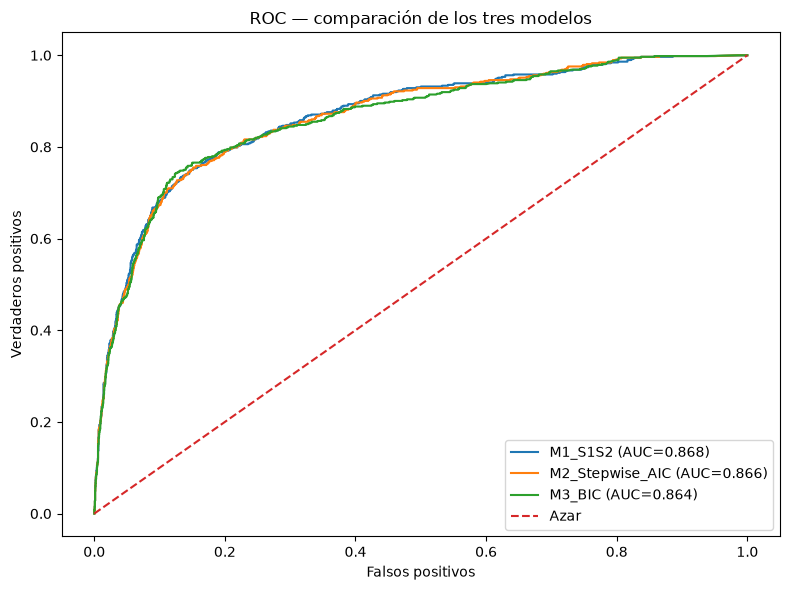

In [17]:
plt.figure(figsize=(8,6))
for nombre,(mod,vars_) in modelos.items():
    p=mod.predict(sm.add_constant(Xte_all[vars_],has_constant="add"))
    fpr,tpr,_=roc_curve(yte,p)
    auc=roc_auc_score(yte,p)
    plt.plot(fpr,tpr,label=f"{nombre} (AUC={auc:.3f})")
plt.plot([0,1],[0,1],"--",label="Azar")
plt.xlabel("Falsos positivos")
plt.ylabel("Verdaderos positivos")
plt.title("ROC — comparación de los tres modelos")
plt.legend()
plt.tight_layout()
plt.show()


## 18. Selección fundamentada del modelo base

La selección del modelo final no se basa exclusivamente en maximizar una única métrica. Se consideran conjuntamente:

1. **Discriminación:** AUC en prueba.
2. **Detección de la clase compra:** recall y F1.
3. **Parsimonia:** número de predictores.
4. **Estabilidad e interpretabilidad:** significancia y coherencia de los coeficientes.
5. **Contexto:** `Revenue=1` es minoritaria, por lo que accuracy por sí sola no es suficiente.

Los resultados muestran un desempeño muy similar entre los tres modelos. M1 presenta el mayor AUC de prueba (**0,8683**), mientras M2 obtiene el mayor recall (**35,66 %**) y F1 (**0,4811**). M3 alcanza AUC **0,8637**, a solo 0,0046 del mejor modelo, con una especificación más parsimoniosa de cuatro predictores.

Dado que la pérdida de AUC respecto del máximo es inferior a 0,005 y M3 conserva capacidad discriminativa alta con menor complejidad, se selecciona **M3-BIC como modelo base final**. Esta decisión privilegia parsimonia sin sacrificar materialmente el desempeño predictivo. Posteriormente se evalúa ponderación de clases para abordar específicamente el bajo recall de la clase compra.


In [18]:
test_metrics = metricas_modelos.query("Split == 'Test'").copy()
test_metrics["n_variables"] = test_metrics["Modelo"].map({
    k: len(v[1]) for k,v in modelos.items()
})

# Regla explícita:
# 1) identificar el AUC máximo;
# 2) considerar equivalentes los modelos a <= 0.005 del máximo;
# 3) entre ellos elegir el más parsimonioso;
# 4) usar F1 como desempate.
best_auc = test_metrics["AUC"].max()
test_metrics["Delta_AUC_mejor"] = best_auc - test_metrics["AUC"]
candidatos_best = test_metrics[test_metrics["Delta_AUC_mejor"] <= .005].copy()

seleccion = candidatos_best.sort_values(
    ["n_variables", "F1"],
    ascending=[True, False]
).iloc[0]

BEST_NAME = seleccion["Modelo"]
best_model, BEST_VARS = modelos[BEST_NAME]

display(test_metrics.round(4))
print("Mejor AUC observado:", round(best_auc, 4))
print("Modelos dentro de 0.005 del mejor AUC:")
display(candidatos_best.round(4))
print("Modelo seleccionado por parsimonia:", BEST_NAME)
print("Variables:", BEST_VARS)


,Modelo,Split,Accuracy,Precision,Recall,F1,AUC,n_variables,Delta_AUC_mejor
1,M1_S1S2,Test,0.8816,0.7519,0.3497,0.4773,0.8683,6,0.0000
3,M2_Stepwise_AIC,Test,0.8810,0.7391,0.3566,0.4811,0.8662,6,0.0020
5,M3_BIC,Test,0.8800,0.7370,0.3479,0.4727,0.8637,4,0.0046


Mejor AUC observado: 0.8683
Modelos dentro de 0.005 del mejor AUC:


,Modelo,Split,Accuracy,Precision,Recall,F1,AUC,n_variables,Delta_AUC_mejor
1,M1_S1S2,Test,0.8816,0.7519,0.3497,0.4773,0.8683,6,0.0000
3,M2_Stepwise_AIC,Test,0.8810,0.7391,0.3566,0.4811,0.8662,6,0.0020
5,M3_BIC,Test,0.8800,0.7370,0.3479,0.4727,0.8637,4,0.0046


Modelo seleccionado por parsimonia: M3_BIC
Variables: ['ProductRelated', 'ExitRates', 'PageValues', 'SpecialDay']


# PARTE III — Mejora del recall mediante ponderación de clases

## 19. Class weighting

El modelo base M3-BIC presenta buen poder discriminativo global, pero con umbral 0,5 identifica solo una fracción de las compras reales. Dado el desbalance de `Revenue`, se evalúa `class_weight='balanced'` como análisis predictivo complementario.

En prueba, la ponderación aumenta el **recall desde 34,79 % hasta 71,15 %** y el **F1 desde 47,27 % hasta 61,71 %**. El costo es una reducción de precision (**73,70 % → 54,48 %**) y accuracy (**88,00 % → 86,35 %**), debido al aumento de falsos positivos. El AUC se mantiene alto e incluso aumenta levemente (**0,8638 → 0,8694**).

Por tanto, si el objetivo de decisión prioriza **detectar sesiones con probabilidad de compra** y el costo de omitir compradores potenciales es relevante, la versión ponderada resulta más útil. Si el costo de falsos positivos fuese alto, debería evaluarse el umbral de clasificación según el contexto operativo.


In [19]:
clf_unweighted = LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)
clf_weighted = LogisticRegression(max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE)

clf_unweighted.fit(Xtr_all[BEST_VARS], ytr)
clf_weighted.fit(Xtr_all[BEST_VARS], ytr)

rows=[]
for nombre, clf in [("Sin ponderación",clf_unweighted),("Class weight balanced",clf_weighted)]:
    for split,X,y in [("Train",Xtr_all,ytr),("Test",Xte_all,yte)]:
        p=clf.predict_proba(X[BEST_VARS])[:,1]
        pred=clf.predict(X[BEST_VARS])
        rows.append({
            "Versión":nombre,"Split":split,
            "Accuracy":accuracy_score(y,pred),
            "Precision":precision_score(y,pred,zero_division=0),
            "Recall":recall_score(y,pred,zero_division=0),
            "F1":f1_score(y,pred,zero_division=0),
            "AUC":roc_auc_score(y,p)
        })
tabla_weight=pd.DataFrame(rows)
display(tabla_weight.round(4))


,Versión,Split,Accuracy,Precision,Recall,F1,AUC
0,Sin ponderación,Train,0.8848,0.7568,0.3772,0.5035,0.8897
1,Sin ponderación,Test,0.8800,0.7370,0.3479,0.4727,0.8638
2,Class weight balanced,Train,0.8782,0.5824,0.7537,0.6571,0.8944
3,Class weight balanced,Test,0.8635,0.5448,0.7115,0.6171,0.8694


## 20. Modelo final para inferencia

La ponderación de clases se usa como análisis predictivo complementario para mejorar sensibilidad. Para bootstrap de coeficientes, OR, IC tradicionales y diagnósticos inferenciales se mantiene el `statsmodels.Logit` del modelo base seleccionado, garantizando comparabilidad directa de parámetros.


# PARTE IV — Diagnósticos del modelo seleccionado

## 21. Multicolinealidad mediante VIF

El VIF máximo observado es aproximadamente **1,137**, muy por debajo de los umbrales usuales de preocupación. Por tanto, no existe evidencia de multicolinealidad problemática entre los predictores del M3-BIC. Esto es consistente con la decisión de S1/S2 de evitar incorporar simultáneamente pares fuertemente correlacionados.


In [20]:
X_vif=Xtr_all[BEST_VARS].astype(float)
tabla_vif=pd.DataFrame({
    "Variable":X_vif.columns,
    "VIF":[variance_inflation_factor(X_vif.values,i) for i in range(X_vif.shape[1])]
}).sort_values("VIF",ascending=False)
display(tabla_vif.round(3))


,Variable,VIF
1,ExitRates,1.137
0,ProductRelated,1.096
2,PageValues,1.036
3,SpecialDay,1.013


## 22. Linealidad en el logit — Box-Tidwell aproximado

Para los predictores continuos se evalúa la interacción `x × log(x)`. El diagnóstico entrega resultados diferentes:

- `ExitRates`: p ≈ **0,5898**, sin evidencia de desviación relevante de linealidad en el logit.
- `PageValues`: **p < 0,001**, evidenciando una posible relación no lineal con el logit de compra.

Por tanto, el supuesto de linealidad no se cumple completamente para `PageValues`. Esto **no se oculta ni se interpreta como causalidad**: se registra como una limitación del modelo logístico lineal. Una extensión futura podría evaluar una transformación o especificación no lineal de `PageValues`, manteniendo la comparabilidad de esta entrega con los métodos solicitados en el curso.


In [21]:
CONTINUAS_CAND = [
    "Administrative_Duration","Informational_Duration",
    "ProductRelated_Duration","BounceRates","ExitRates","PageValues"
]
continuas_best=[v for v in BEST_VARS if v in CONTINUAS_CAND]

bt_base=train_main.copy()
bt_y=bt_base["Revenue"].astype(int)
bt_cols={}

for v in continuas_best:
    x=bt_base[v].astype(float)
    eps=max(1e-6, (x[x>0].min()/2 if (x>0).any() else 1e-6))
    z=x+eps
    bt_cols[v]=z
    bt_cols[v+"_xlogx"]=z*np.log(z)

if continuas_best:
    bt_df=pd.DataFrame(bt_cols,index=bt_base.index)
    bt_X=sm.add_constant(bt_df,has_constant="add")
    bt_mod=sm.Logit(bt_y,bt_X).fit(disp=False)
    bt_terms=[v+"_xlogx" for v in continuas_best]
    display(pd.DataFrame({
        "Término":bt_terms,
        "p_value":[bt_mod.pvalues[t] for t in bt_terms]
    }).round(4))
else:
    print("El modelo seleccionado no contiene variables continuas para este diagnóstico.")


,Término,p_value
0,ExitRates_xlogx,0.5898
1,PageValues_xlogx,0.0000


## 23. Residuos e influencia

Se inspeccionan residuos de Pearson, leverage y distancia de Cook. Los puntos señalados se consideran **observaciones a revisar**, no errores que deban eliminarse automáticamente.


,count,mean,std,min,25%,50%,75%,max
resid_pearson,8631.0,-1.3175,104.9466,-9707.3883,-0.3418,-0.2724,-0.1250,18.6243
leverage,8631.0,0.0006,0.0011,0.0000,0.0002,0.0003,0.0005,0.0309
cooks_d,8631.0,0.0002,0.0015,0.0000,0.0000,0.0000,0.0000,0.0882


Cook > 4/n: 427
Leverage alto: 971


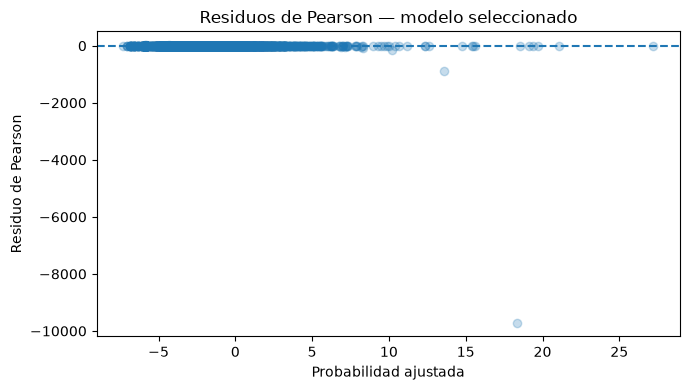

,resid_pearson,leverage,cooks_d,cooks_alerta,leverage_alerta
5773,-9707.3883,0.0000,0.0882,True,False
10640,-885.5106,0.0000,0.0478,True,False
5152,-2.4865,0.0229,0.0297,True,True
7938,-164.0482,0.0000,0.0288,True,False
6684,-2.1396,0.0269,0.0260,True,True
7600,18.5176,0.0004,0.0256,True,False
6700,18.6243,0.0004,0.0256,True,False
12247,-64.3151,0.0000,0.0255,True,False
3200,-60.6964,0.0000,0.0201,True,False
8308,-2.1680,0.0183,0.0179,True,True


In [22]:
infl = best_model.get_influence()
sf = infl.summary_frame()

diag = pd.DataFrame({
    "resid_pearson": best_model.resid_pearson,
    "leverage": sf["hat_diag"],
    "cooks_d": sf["cooks_d"]
}, index=Xtr_all.index)

n=len(diag)
diag["cooks_alerta"]=diag["cooks_d"] > 4/n
diag["leverage_alerta"]=diag["leverage"] > 2*(len(BEST_VARS)+1)/n

display(diag.describe().T.round(4))
print("Cook > 4/n:", int(diag["cooks_alerta"].sum()))
print("Leverage alto:", int(diag["leverage_alerta"].sum()))

plt.figure(figsize=(7,4))
plt.scatter(best_model.fittedvalues,best_model.resid_pearson,alpha=.25)
plt.axhline(0,linestyle="--")
plt.xlabel("Probabilidad ajustada")
plt.ylabel("Residuo de Pearson")
plt.title("Residuos de Pearson — modelo seleccionado")
plt.tight_layout()
plt.show()

display(diag.sort_values("cooks_d",ascending=False).head(10).round(4))


# PARTE V — Bootstrap del mejor modelo

## 24. Estabilidad de coeficientes y odds ratios

Se realizaron **1.000 remuestras bootstrap exitosas, sin fallos**, reajustando en cada una la misma especificación M3-BIC.

Los intervalos bootstrap al 95 % de los cuatro predictores seleccionados mantienen el signo de los coeficientes y no incluyen 0; de forma equivalente, los intervalos de los odds ratios no incluyen 1. Además, las conclusiones son consistentes con los intervalos tradicionales del modelo.

Esto respalda la **estabilidad de los parámetros del modelo seleccionado** frente a variaciones muestrales, fortaleciendo la evidencia obtenida en el ajuste original.


In [23]:
rng=np.random.default_rng(RANDOM_STATE)
boot_coefs=[]
fallos=0

Xb_full=Xtr_all[BEST_VARS]
yb_full=ytr

for b in range(BOOTSTRAP_B):
    pos=rng.integers(0,len(Xb_full),len(Xb_full))
    Xb=Xb_full.iloc[pos]
    yb=yb_full.iloc[pos]
    try:
        mb=sm.Logit(yb,sm.add_constant(Xb,has_constant="add")).fit(disp=False,maxiter=100)
        boot_coefs.append(mb.params.reindex(["const"]+BEST_VARS).values)
    except Exception:
        fallos+=1

boot=pd.DataFrame(boot_coefs,columns=["const"]+BEST_VARS)
print("Bootstrap exitosos:",len(boot),"| fallos:",fallos)

trad_ci=best_model.conf_int().reindex(boot.columns)
rows=[]
for v in boot.columns:
    lo,hi=np.percentile(boot[v],[2.5,97.5])
    rows.append({
        "Variable":v,
        "Coef_original":best_model.params[v],
        "IC_trad_coef_inf":trad_ci.loc[v,0],
        "IC_trad_coef_sup":trad_ci.loc[v,1],
        "IC_boot_coef_inf":lo,
        "IC_boot_coef_sup":hi,
        "OR_original":np.exp(best_model.params[v]),
        "IC_boot_OR_inf":np.exp(lo),
        "IC_boot_OR_sup":np.exp(hi),
        "Estable_boot": not (lo <= 0 <= hi)
    })
tabla_boot=pd.DataFrame(rows)
display(tabla_boot.round(4))


Bootstrap exitosos: 1000 | fallos: 0


,Variable,Coef_original,IC_trad_coef_inf,IC_trad_coef_sup,IC_boot_coef_inf,IC_boot_coef_sup,OR_original,IC_boot_OR_inf,IC_boot_OR_sup,Estable_boot
0,const,-2.2382,-2.3447,-2.1316,-2.3524,-2.1464,0.1067,0.0951,0.1169,True
1,ProductRelated,0.2482,0.1917,0.3046,0.1861,0.3141,1.2817,1.2045,1.3690,True
2,ExitRates,-0.9299,-1.1240,-0.7358,-1.1306,-0.7555,0.3946,0.3228,0.4698,True
3,PageValues,1.5098,1.4077,1.6120,1.3347,1.7101,4.5260,3.7988,5.5293,True
4,SpecialDay,-0.2454,-0.3568,-0.1340,-0.3587,-0.1540,0.7824,0.6986,0.8573,True


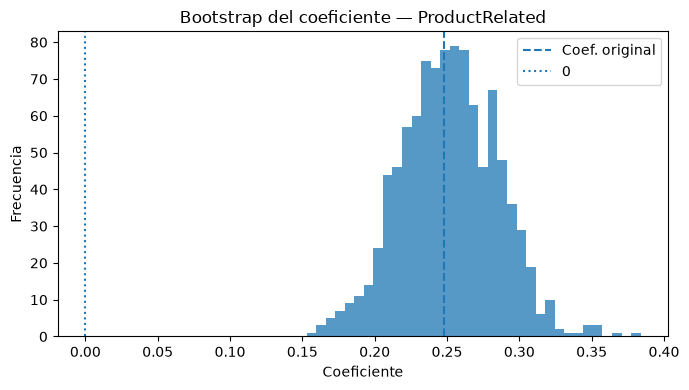

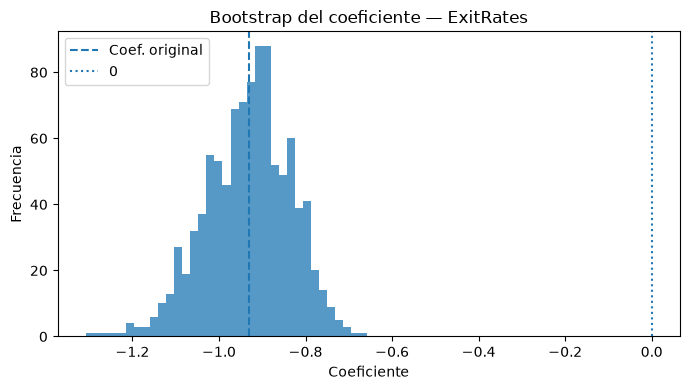

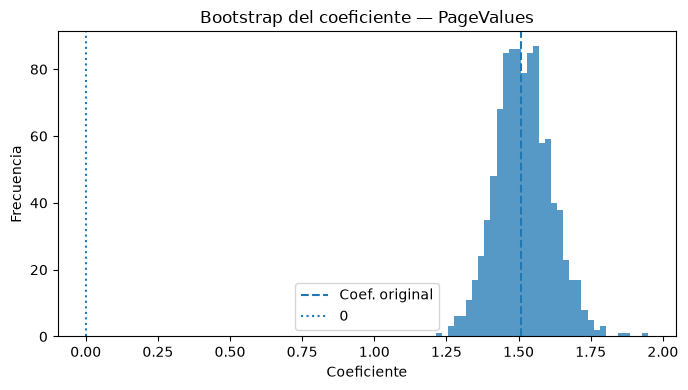

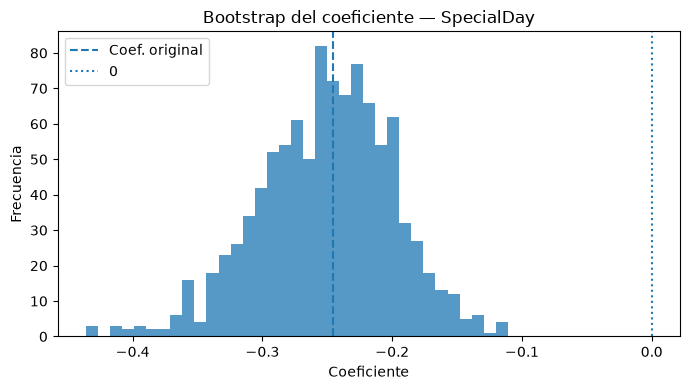

In [24]:
for v in [x for x in boot.columns if x!="const"]:
    plt.figure(figsize=(7,4))
    plt.hist(boot[v],bins=35,alpha=.75)
    plt.axvline(best_model.params[v],linestyle="--",label="Coef. original")
    plt.axvline(0,linestyle=":",label="0")
    plt.title(f"Bootstrap del coeficiente — {v}")
    plt.xlabel("Coeficiente")
    plt.ylabel("Frecuencia")
    plt.legend()
    plt.tight_layout()
    plt.show()


# PARTE VI — Impacto de la imputación sobre el modelo final

## 25. Ajuste del mismo modelo final sobre las tres estrategias

Se reajusta exactamente la misma especificación M3-BIC bajo eliminación, mediana e imputación por regresión.

En prueba:
- **Eliminación:** AUC ≈ 0,8559.
- **Mediana:** AUC ≈ 0,8619.
- **Regresión:** AUC ≈ 0,8637.

La eliminación presenta una accuracy ligeramente competitiva, pero reduce sustancialmente la muestra: se pierden aproximadamente **1.936 observaciones de entrenamiento y 836 de prueba** respecto de las estrategias de imputación. La regresión, en cambio, conserva el tamaño muestral y obtiene el mayor AUC entre las tres alternativas.

En conjunto con el menor error de imputación y la mejor preservación de correlaciones, estos resultados sustentan el uso de **imputación por regresión** como estrategia principal. Las conclusiones sustantivas del modelo se mantienen entre estrategias, lo que sugiere robustez frente al tratamiento de faltantes.


In [25]:
estrategias_modelo={
    "Eliminación":(train_del,test_del),
    "Mediana":(train_med,test_med),
    "Regresión":(train_reg,test_reg)
}

comparacion_imp=[]
coef_imp=[]

for estrategia,(tr,te) in estrategias_modelo.items():
    Xtr,Xte,_=preparar_matrices(tr,te)
    ytr_e=tr["Revenue"].astype(int)
    yte_e=te["Revenue"].astype(int)

    mod=fit_logit(Xtr,ytr_e,BEST_VARS)
    p=mod.predict(sm.add_constant(Xte[BEST_VARS],has_constant="add"))
    pred=(p>=.5).astype(int)

    comparacion_imp.append({
        "Estrategia":estrategia,
        "n_train":len(tr),"n_test":len(te),
        "Accuracy_test":accuracy_score(yte_e,pred),
        "Precision_test":precision_score(yte_e,pred,zero_division=0),
        "Recall_test":recall_score(yte_e,pred,zero_division=0),
        "F1_test":f1_score(yte_e,pred,zero_division=0),
        "AUC_test":roc_auc_score(yte_e,p)
    })

    ci=mod.conf_int()
    for v in ["const"]+BEST_VARS:
        coef_imp.append({
            "Estrategia":estrategia,"Variable":v,
            "Coef":mod.params[v],
            "OR":np.exp(mod.params[v]),
            "IC95_OR_inf":np.exp(ci.loc[v,0]),
            "IC95_OR_sup":np.exp(ci.loc[v,1])
        })

tabla_impacto=pd.DataFrame(comparacion_imp)
tabla_coef_imp=pd.DataFrame(coef_imp)

display(tabla_impacto.round(4))
display(tabla_coef_imp.round(4))


,Estrategia,n_train,n_test,Accuracy_test,Precision_test,Recall_test,F1_test,AUC_test
0,Eliminación,6695,2863,0.8847,0.7308,0.3568,0.4795,0.8559
1,Mediana,8631,3699,0.8794,0.7316,0.3479,0.4716,0.8619
2,Regresión,8631,3699,0.8800,0.7370,0.3479,0.4727,0.8637


,Estrategia,Variable,Coef,OR,IC95_OR_inf,IC95_OR_sup
0,Eliminación,const,-2.3368,0.0966,0.0845,0.1105
1,Eliminación,ProductRelated,0.2443,1.2767,1.1976,1.3610
2,Eliminación,ExitRates,-1.1101,0.3295,0.2588,0.4196
3,Eliminación,PageValues,1.5321,4.6281,4.1181,5.2011
4,Eliminación,SpecialDay,-0.2485,0.7799,0.6848,0.8883
5,Mediana,const,-2.2433,0.1061,0.0953,0.1182
6,Mediana,ProductRelated,0.2579,1.2943,1.2235,1.3691
7,Mediana,ExitRates,-0.9542,0.3851,0.3148,0.4712
8,Mediana,PageValues,1.5223,4.5826,4.1387,5.0741
9,Mediana,SpecialDay,-0.2536,0.7760,0.6943,0.8674


# PARTE VII — Sensibilidad a `PageValues`

## 26. Modelo con y sin `PageValues`

`PageValues` es una variable fuertemente asociada con `Revenue`, pero conceptualmente es próxima al resultado de compra. Por esta razón se mantiene una cautela explícita respecto de su interpretación y se compara el desempeño del modelo con y sin ella.

El propósito no es declarar `PageValues` inválida, sino determinar cuánto depende la capacidad discriminativa del modelo de una variable que puede reflejar información muy cercana al desenlace. La diferencia de métricas obtenida al retirarla debe reportarse como **análisis de sensibilidad**, no como evidencia causal.


In [26]:
if "PageValues" in BEST_VARS and len(BEST_VARS)>1:
    vars_sin_page=[v for v in BEST_VARS if v!="PageValues"]
    mod_sin=fit_logit(Xtr_all,ytr,vars_sin_page)

    rows=[]
    for nombre,mod,vars_ in [
        ("Final con PageValues",best_model,BEST_VARS),
        ("Sensibilidad sin PageValues",mod_sin,vars_sin_page)
    ]:
        p=mod.predict(sm.add_constant(Xte_all[vars_],has_constant="add"))
        pred=(p>=.5).astype(int)
        rows.append({
            "Modelo":nombre,
            "Accuracy":accuracy_score(yte,pred),
            "Precision":precision_score(yte,pred,zero_division=0),
            "Recall":recall_score(yte,pred,zero_division=0),
            "F1":f1_score(yte,pred,zero_division=0),
            "AUC":roc_auc_score(yte,p)
        })
    display(pd.DataFrame(rows).round(4))
else:
    print("PageValues no pertenece al modelo final; no corresponde retirarla.")


,Modelo,Accuracy,Precision,Recall,F1,AUC
0,Final con PageValues,0.8800,0.7370,0.3479,0.4727,0.8637
1,Sensibilidad sin PageValues,0.8451,0.4706,0.0140,0.0272,0.7008


# PARTE VIII — Síntesis automática de resultados

La siguiente celda imprime los principales resultados numéricos para facilitar la redacción del informe final. La interpretación académica debe mantener lenguaje de **asociación**, no causalidad.


In [27]:
print("=== RESUMEN S3 ===")
print("Estrategia principal de imputación:", METODO_PRINCIPAL)
print("Modelo base seleccionado:", BEST_NAME)
print("Variables:", BEST_VARS)

print("\nMétricas test de los tres modelos:")
display(test_metrics.round(4))

print("\nPonderación de clases:")
display(tabla_weight.query("Split=='Test'").round(4))

print("\nBootstrap:")
display(tabla_boot.round(4))

print("\nImpacto de imputación:")
display(tabla_impacto.round(4))


=== RESUMEN S3 ===
Estrategia principal de imputación: Regresión
Modelo base seleccionado: M3_BIC
Variables: ['ProductRelated', 'ExitRates', 'PageValues', 'SpecialDay']

Métricas test de los tres modelos:


,Modelo,Split,Accuracy,Precision,Recall,F1,AUC,n_variables,Delta_AUC_mejor
1,M1_S1S2,Test,0.8816,0.7519,0.3497,0.4773,0.8683,6,0.0000
3,M2_Stepwise_AIC,Test,0.8810,0.7391,0.3566,0.4811,0.8662,6,0.0020
5,M3_BIC,Test,0.8800,0.7370,0.3479,0.4727,0.8637,4,0.0046



Ponderación de clases:


,Versión,Split,Accuracy,Precision,Recall,F1,AUC
1,Sin ponderación,Test,0.8800,0.7370,0.3479,0.4727,0.8638
3,Class weight balanced,Test,0.8635,0.5448,0.7115,0.6171,0.8694



Bootstrap:


,Variable,Coef_original,IC_trad_coef_inf,IC_trad_coef_sup,IC_boot_coef_inf,IC_boot_coef_sup,OR_original,IC_boot_OR_inf,IC_boot_OR_sup,Estable_boot
0,const,-2.2382,-2.3447,-2.1316,-2.3524,-2.1464,0.1067,0.0951,0.1169,True
1,ProductRelated,0.2482,0.1917,0.3046,0.1861,0.3141,1.2817,1.2045,1.3690,True
2,ExitRates,-0.9299,-1.1240,-0.7358,-1.1306,-0.7555,0.3946,0.3228,0.4698,True
3,PageValues,1.5098,1.4077,1.6120,1.3347,1.7101,4.5260,3.7988,5.5293,True
4,SpecialDay,-0.2454,-0.3568,-0.1340,-0.3587,-0.1540,0.7824,0.6986,0.8573,True



Impacto de imputación:


,Estrategia,n_train,n_test,Accuracy_test,Precision_test,Recall_test,F1_test,AUC_test
0,Eliminación,6695,2863,0.8847,0.7308,0.3568,0.4795,0.8559
1,Mediana,8631,3699,0.8794,0.7316,0.3479,0.4716,0.8619
2,Regresión,8631,3699,0.8800,0.7370,0.3479,0.4727,0.8637


# 27. Conclusiones integradas

El desarrollo de S3 mantiene la progresión metodológica **S1 → S2 → S3**. S1 permitió caracterizar el desbalance de `Revenue`, la asimetría de las variables y las principales asociaciones; S2 confirmó mediante remuestreo la estabilidad de correlaciones relevantes y mostró que los valores extremos afectan algunos estimadores sin que una sola observación domine los resultados. Sobre esa evidencia se construyó el modelamiento final.

### Manejo de faltantes
La base original no contenía datos faltantes. Para aplicar los métodos requeridos se generó de forma reproducible un **12 % MCAR** en `ProductRelated_Duration` y `ExitRates`, sin modificar `Revenue`. La imputación por regresión superó claramente a la mediana: el RMSE de `ProductRelated_Duration` disminuyó aproximadamente de **1860,85 a 832,33**, y el de `ExitRates` de **0,0471 a 0,0195**. Además, la regresión preservó mejor las correlaciones observadas previamente. Por ello se seleccionó como estrategia principal.

### Comparación de modelos
Los tres modelos logísticos presentaron desempeño similar. M1 obtuvo el mayor AUC de prueba (**0,8683**), M2 el mayor recall (**35,66 %**) y F1 (**0,4811**), mientras M3-BIC alcanzó AUC **0,8637** con solo cuatro predictores. Al encontrarse a menos de 0,005 del mejor AUC, se seleccionó **M3-BIC** por parsimonia y capacidad discriminativa comparable.

El modelo seleccionado incluye `ProductRelated`, `ExitRates`, `PageValues` y `SpecialDay`. Sus asociaciones deben interpretarse mediante coeficientes y odds ratios manteniendo un alcance **asociativo**, no causal.

### Desbalance y class weighting
Con umbral 0,5, el modelo sin ponderación presentó recall de aproximadamente **34,79 %**. Con `class_weight='balanced'`, el recall aumentó a **71,15 %** y el F1 a **61,71 %**, mientras la accuracy disminuyó moderadamente de **88,00 % a 86,35 %** y la precision de **73,70 % a 54,48 %**. Esto evidencia un intercambio entre sensibilidad y falsos positivos. Para un contexto donde detectar compradores potenciales sea prioritario, la ponderación ofrece una alternativa operativamente más sensible.

### Diagnóstico y estabilidad
El VIF máximo fue cercano a **1,137**, sin evidencia de multicolinealidad problemática. El diagnóstico de linealidad en el logit no mostró problemas para `ExitRates`, pero sí evidencia de no linealidad para `PageValues` (**p < 0,001**), lo que constituye una limitación que debe considerarse en futuras extensiones.

El bootstrap se completó con **1.000 remuestras exitosas y 0 fallos**. Los intervalos bootstrap de los predictores del M3-BIC mantuvieron sus signos y los intervalos de OR no incluyeron 1, respaldando la estabilidad de los parámetros.

### Impacto de la imputación
El modelo final alcanzó AUC aproximados de **0,8559 con eliminación**, **0,8619 con mediana** y **0,8637 con regresión**. La eliminación implica además una pérdida considerable de observaciones. Por tanto, la imputación por regresión ofrece el mejor equilibrio entre conservación de información, calidad de imputación y desempeño predictivo.

### Respuesta a la pregunta de investigación
Los resultados indican que características relacionadas con la interacción con productos, la tasa de salida, el valor económico asociado a las páginas visitadas y la proximidad temporal a fechas especiales presentan asociaciones relevantes con la probabilidad de que una sesión termine en compra. Entre ellas, `PageValues` aporta una capacidad discriminativa importante, aunque requiere cautela por su proximidad conceptual al desenlace y por la evidencia de no linealidad detectada.

En síntesis, los resultados son consistentes entre las fases del proyecto y robustos frente a diferentes estrategias de tratamiento de faltantes. Sin embargo, las asociaciones observadas **no permiten establecer causalidad**.


## Nota de reproducibilidad

Después de esta corrección metodológica, ejecutar **Restart Kernel → Run All** antes de entregar. La regla de selección quedó explícita y las conclusiones se encuentran alineadas con los resultados obtenidos en la ejecución revisada.


# 28. Checklist de rúbrica

### Imputación y faltantes
- [x] Referencia explícita a S1.
- [x] MCAR documentado.
- [x] Regresión lineal múltiple con 3–5 predictores.
- [x] Diagnóstico de regresiones de imputación.
- [x] Eliminación vs. mediana vs. regresión.
- [x] MAE/RMSE aprovechando valores verdaderos.
- [x] Tamaño, distribución y correlaciones comparados.

### Regresión logística
- [x] 70/30 estratificado.
- [x] Decisión sobre outliers fundamentada en S1/S2.
- [x] Estandarización y codificación.
- [x] Modelo 1 informado por S1/S2.
- [x] Modelo 2 stepwise AIC.
- [x] Modelo 3 BIC.
- [x] Coeficientes y OR.
- [x] Train/test: matriz, accuracy, precision, recall, F1 y AUC.
- [x] ROC comparativa.
- [x] Class weighting como mejora de recall.

### Estabilidad y diagnóstico
- [x] Bootstrap de coeficientes.
- [x] IC bootstrap de coeficientes y OR.
- [x] Comparación con IC tradicionales.
- [x] VIF.
- [x] Linealidad en el logit.
- [x] Residuos.
- [x] Influencia.

### Impacto de imputación
- [x] Mismo modelo final en los tres datasets.
- [x] Tamaño muestral.
- [x] Coeficientes, OR e IC.
- [x] Accuracy y AUC.
- [x] Recomendación basada en evidencia.

### Integración
- [x] Narrativa S1 → S2 → S3.
- [x] Análisis de sensibilidad de `PageValues`.
- [x] Semilla y flujo reproducible.
